# 16b · Routing with abstention and separate authority

## The engineering question
Can similarity choose a useful intent while declining ambiguous or out-of-scope requests?

**Learning outcomes:** build intent prototypes; calibrate threshold/margin on development data; freeze them for test evaluation; measure abstention and errors; keep tool authorization outside routing.

Routing compares each query with labeled prototype embeddings and keeps the best score per intent. It accepts only when both the best score and separation from the runner-up exceed thresholds. Development examples include an ambiguous reset/export request and an unrelated poem. A route is a classification suggestion. It never grants permission to reset a device or export private data.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("16b", "B", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


In [2]:
import json

fixtures = json.loads((root() / "datasets/applications.json").read_text())

,split,text,expected,intent,best_intent,score,margin,authorized,correct
0,development,Is my switch currently connected?,status,abstain,status,0.294373,0.030538,False,False
1,development,Delete all settings and reset the router,reset,reset,reset,0.902574,0.433453,False,True
2,development,Save the config as a backup file,export,export,export,0.824110,0.385559,False,True
3,development,Write a poem about the moon,abstain,abstain,export,0.080932,0.016973,False,True
4,development,"Reset or export, which should I choose?",abstain,abstain,reset,0.392933,0.043538,False,True
5,test,Report device uptime and connection health,status,abstain,status,0.667599,0.461262,False,False
6,test,Return this switch to its factory state,reset,abstain,reset,0.496971,0.260207,False,False
7,test,I need a downloadable settings backup,export,abstain,export,0.663598,0.295978,False,False
8,test,Buy two airplane tickets,abstain,abstain,reset,0.091858,0.025207,False,True
9,test,Explain the philosophy of consciousness,abstain,abstain,reset,0.067182,0.002445,False,True


Frozen development configuration: {'threshold': 0.7, 'margin': 0.2, 'development_accuracy': np.float64(0.8)}


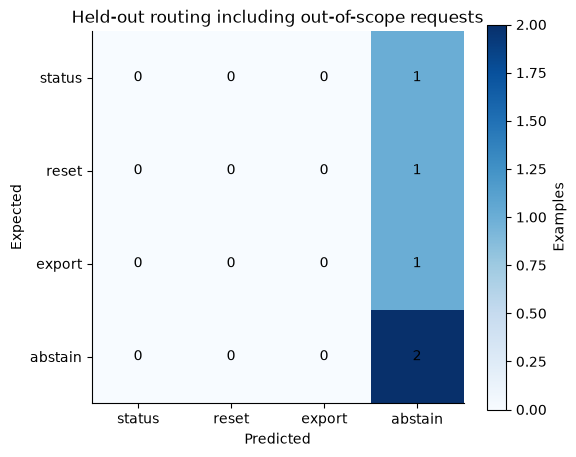

In [3]:
from sklearn.metrics import confusion_matrix
from vector_masterclass.models import embed
from vector_masterclass.applications import route

cfg = fixtures["routing"]
train_text, labels = zip(*cfg["train"])
prototypes = embed(list(train_text))
dev_vectors = embed([t for t, l in cfg["development"]], role="query")
sweeps = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    for margin in [0, 0.05, 0.1, 0.2]:
        predictions = [
            route(v, prototypes, labels, threshold=threshold, margin=margin)["intent"]
            for v in dev_vectors
        ]
        sweeps.append(
            {
                "threshold": threshold,
                "margin": margin,
                "development_accuracy": np.mean(
                    [p == label for p, (_, label) in zip(predictions, cfg["development"])]
                ),
            }
        )
chosen = sorted(sweeps, key=lambda r: (-r["development_accuracy"], -r["threshold"], -r["margin"]))[
    0
]
rows = []
for split in ["development", "test"]:
    for (text, label), vector in zip(cfg[split], embed([t for t, l in cfg[split]], role="query")):
        prediction = route(
            vector, prototypes, labels, threshold=chosen["threshold"], margin=chosen["margin"]
        )
        rows.append(
            {
                "split": split,
                "text": text,
                "expected": label,
                **prediction,
                "correct": prediction["intent"] == label,
            }
        )
results = lesson.table(pd.DataFrame(rows))
lesson.table(pd.DataFrame(sweeps), "development-calibration")
display(results)
print("Frozen development configuration:", chosen)
test = results[results.split.eq("test")]
categories = ["status", "reset", "export", "abstain"]
cm = confusion_matrix(test.expected, test.intent, labels=categories)
fig, ax = plt.subplots(figsize=(6, 5))
picture = ax.imshow(cm, cmap="Blues", vmin=0)
ax.set(
    xticks=range(4),
    xticklabels=categories,
    yticks=range(4),
    yticklabels=categories,
    xlabel="Predicted",
    ylabel="Expected",
    title="Held-out routing including out-of-scope requests",
)
for i in range(4):
    for j in range(4):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(picture, ax=ax, label="Examples")
lesson.figure(fig)
plt.show()

## Interpretation and exercise
Raising thresholds can improve accepted-request precision while reducing coverage. Overall accuracy hides that tradeoff, so inspect accepted and abstained examples separately. A high similarity to a destructive intent is not authorization. The caller still needs a verified identity, policy permission, validated arguments, and the applicable action approval boundary.

**Exercise:** add “restart without erasing settings” to development data and inspect confusion with factory reset. Add a new prototype only after defining a distinct intent and corresponding policy. Explain why a prototype copied from the test sentence would invalidate the holdout.

Five test examples are a diagnostic fixture. Production routing requires representative languages, ambiguity, distribution shift, adversarial wording, and safe fallback behavior. Similarity margins are not calibrated confidence probabilities.

In [4]:
manifest = lesson.finish(
    {
        "no_route_grants_authority": bool((~results.authorized).all()),
        "both_splits": set(results.split) == {"development", "test"},
        "out_of_scope_tested": bool(test.expected.eq("abstain").any()),
        "finite_scores": bool(np.isfinite(results.score).all()),
    },
    observations={
        "frozen_parameters": chosen,
        "test_accuracy": float(test.correct.mean()),
        "test_coverage": float(test.intent.ne("abstain").mean()),
        "label_provenance": fixtures["provenance"],
    },
)

{
  "artifact": "artifacts/20261031T055012Z-7d8a7d/16b",
  "checks": {
    "no_route_grants_authority": true,
    "both_splits": true,
    "out_of_scope_tested": true,
    "finite_scores": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.